# Task 2.1: bit-flip relaxation

The computational codewords are approximately $\lvert\pm\alpha\rangle$. We initialize the memory in $\lvert\alpha\rangle$ and the buffer in vacuum, then integrate the supplied two-mode master equation. The only loss channels are $\sqrt{\kappa_a}a$ and $\sqrt{\kappa_b}b$. Across the amplitude sweep, $\epsilon_d=g_2\alpha^2$ changes while the supplied coupling and loss rates remain fixed.

We extract the bit-flip relaxation rate from the real mean amplitude $m(t)=\mathrm{Re}\langle a\rangle$:

$$
m(t)=A e^{-\Gamma_X(t-t_{\mathrm{fit}})},\qquad t_{\mathrm{fit}}=2\ \mathrm{\mu s}.
$$

Here $A$ is a fitted amplitude and $T_X=1/\Gamma_X$. For symmetric transitions at rate $r$ in each direction between well-separated codewords, $\Gamma_X=2r$. At small $\alpha$, the codewords overlap appreciably, so the reported quantity is the observable decay rate specified by the challenge.

The long trajectories use sparse Radau integration of the full two-mode model, with exact changes of basis and representation. Each amplitude is checked with full Dynamiqs integration, decay eigenvalues and independent cutoff increases. No adiabatic elimination or projection onto two cat states is used for the numerical results. The notebook loads saved results by default; set `RERUN=True` to recompute.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RERUN = False


In [2]:
if RERUN:
    from tasks.task_2_1 import main
    main()
result = json.loads((ROOT / "results/task_2_1.json").read_text())
assert result["complete"]
summary = pd.DataFrame([{
    "alpha": row["alpha"], "Gamma (1/us)": row["fit"]["gamma_per_us"],
    "T (us)": row["fit"]["tau_us"], "offset": row["fit"]["offset"],
    "cutoff change (%)": 100*row["checks"]["cutoff_relative_change"],
} for row in result["cases"]])
display(summary)


,alpha,Gamma (1/us),T (us),offset,cutoff change (%)
0,0.70,0.009544,104.775204,0.0,1.913947e-09
1,0.85,0.005120,195.314442,0.0,1.548720e-07
2,1.00,0.002301,434.658672,0.0,5.862457e-06
3,1.15,0.000864,1158.002985,0.0,1.198861e-04
4,1.30,0.000276,3627.867099,0.0,1.331829e-03
5,1.40,0.000120,8319.464124,0.0,4.241134e-03


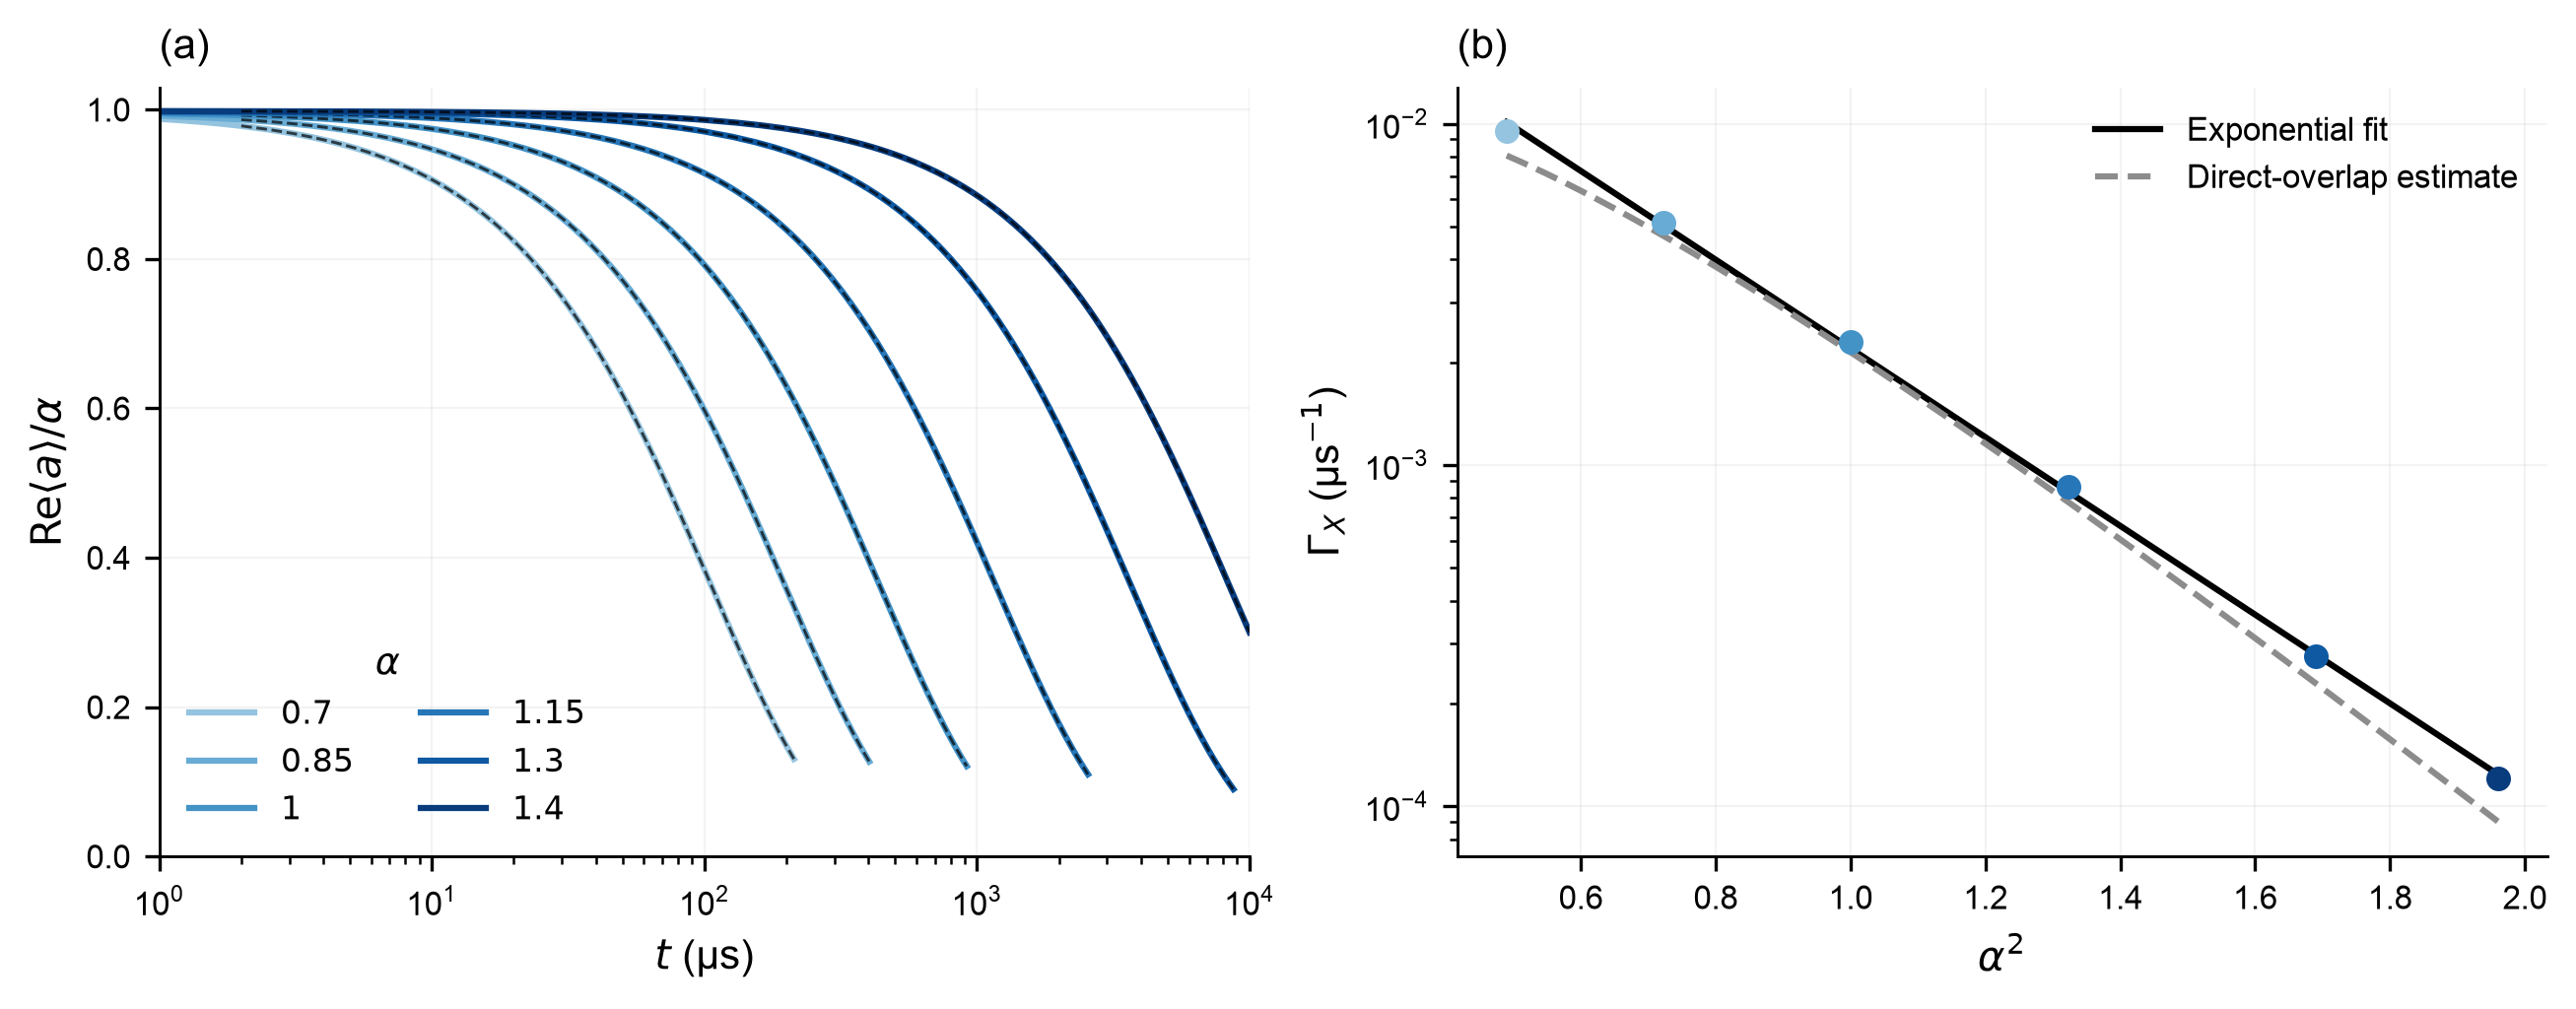

In [3]:
display(Image(filename=str(ROOT / "figures/task_2_1_bit_flips.png")))

**Bit-flip relaxation and exponential suppression.** Full two-mode dynamics from $\lvert\alpha\rangle_a\lvert0\rangle_b$ at $(N_a,N_b)=(20,6)$. Colors identify $\alpha$; the buffer drive is set to $\epsilon_d=g_2\alpha^2$ for each trajectory. (a) Normalized real memory amplitude; colored curves are integrated trajectories and black dashes are exponential fits from 2 µs onward. The logarithmic time axis resolves the different lifetimes and shows times from 1 µs onward. (b) Fitted relaxation rates $\Gamma_X$ versus $\alpha^2$. The black line is the log-linear fit $C_Xe^{-\gamma\alpha^2}$ over $0.7\leq\alpha\leq1.4$; gray dashes show the direct-overlap estimate $2\kappa_a\alpha^2e^{-4\alpha^2}$. Rates are inverse observable decay times, twice symmetric one-way switching rates in the well-separated-codeword limit.

## Interpretation

The direct-overlap estimate follows from

$$
\langle-\alpha\rvert a\lvert\alpha\rangle=\alpha e^{-2\alpha^2},\qquad
\Gamma_X^{\mathrm{GR}}\simeq2\kappa_a\alpha^2e^{-4\alpha^2}.
$$

The factor of two converts a symmetric one-way transition estimate to the observable decay convention. The factor $\alpha^2$ means that fitting this expression over a finite interval to a pure exponential does not return an exponent of exactly four. The report compares the numerical fit and the direct estimate over the same interval.

Finite stabilization also permits loss-induced excursions outside the code space followed by dissipative return. Second-order theory predicts a contribution with $e^{-2\alpha^2}$ scaling even at zero temperature; its single-mode prefactor is not assumed exact for the full memory–buffer model. See [Dubovitskii, Phys. Rev. A 111, 012617 (2025)](https://arxiv.org/html/2407.17299v2) and the [rate report](../docs/task_2_rates.md).

In [4]:
checks = pd.DataFrame([{
    "alpha": row["alpha"],
    "fit/eigenvalue difference (%)": 100*row["checks"]["fit_vs_eigen_relative_change"],
    "Dynamiqs rate difference (%)": 100*row["checks"]["dynamiqs_rate_relative_change"],
    "fitting-window spread (%)": 100*row["checks"]["window_relative_spread"],
    "max memory top-2 (%)": 100*row["diagnostics"]["max_top2_a"],
    "max buffer top-1 (%)": 100*row["diagnostics"]["max_top1_b"],
} for row in result["cases"]])
display(checks)
print("Scaling fit:")
for key, value in result["scaling_fit"].items():
    print(f"  {key}: {value}")


,alpha,fit/eigenvalue difference (%),Dynamiqs rate difference (%),fitting-window spread (%),max memory top-2 (%),max buffer top-1 (%)
0,0.70,6.205691e-07,0.000001,6.169607e-07,2.473810e-19,1.158387e-11
1,0.85,3.281583e-07,0.000001,3.246296e-07,1.814641e-16,3.794297e-10
2,1.00,7.838523e-08,0.000001,7.223460e-08,3.715883e-14,5.637846e-09
3,1.15,7.065362e-08,0.000004,8.297464e-08,2.992582e-12,4.493383e-08
4,1.30,2.635180e-08,0.000006,3.501712e-08,1.200902e-10,2.104166e-07
5,1.40,4.295698e-08,0.000019,5.353085e-08,1.050949e-09,4.508009e-07


Scaling fit:
  exponent: 2.9940654060239495
  prefactor_per_us: 0.043821132631482254
  r_squared: 0.9994565979257406
  max_abs_log_residual: 0.057085997524895404
  alpha_min: 0.7
  alpha_max: 1.4


## Beyond brute force: the challenge cat size

The trajectories above stop at $\alpha=1.4$ for a practical reason. At $\alpha=2.1$ one bit flip takes about 2.6 s, roughly $10^{9}$ times the 1 ns scale of the dynamics, so no time-domain run can resolve it.

The decay rate itself is still accessible. Every relaxation rate of a Lindblad model is an eigenvalue of its Liouvillian $\mathcal L$. The model is symmetric under $a\to-a$, so $\mathcal L$ splits into even and odd blocks. $\mathrm{Re}\langle a\rangle$ lives in the odd block, and $\Gamma_X$ is minus its slowest eigenvalue. A sparse shift-invert solve on that block (`src/spectral.py`, `research/s2/gx_eig.py`) gives $\Gamma_X$ at $\alpha=2.1$ in under a minute, however small it is.

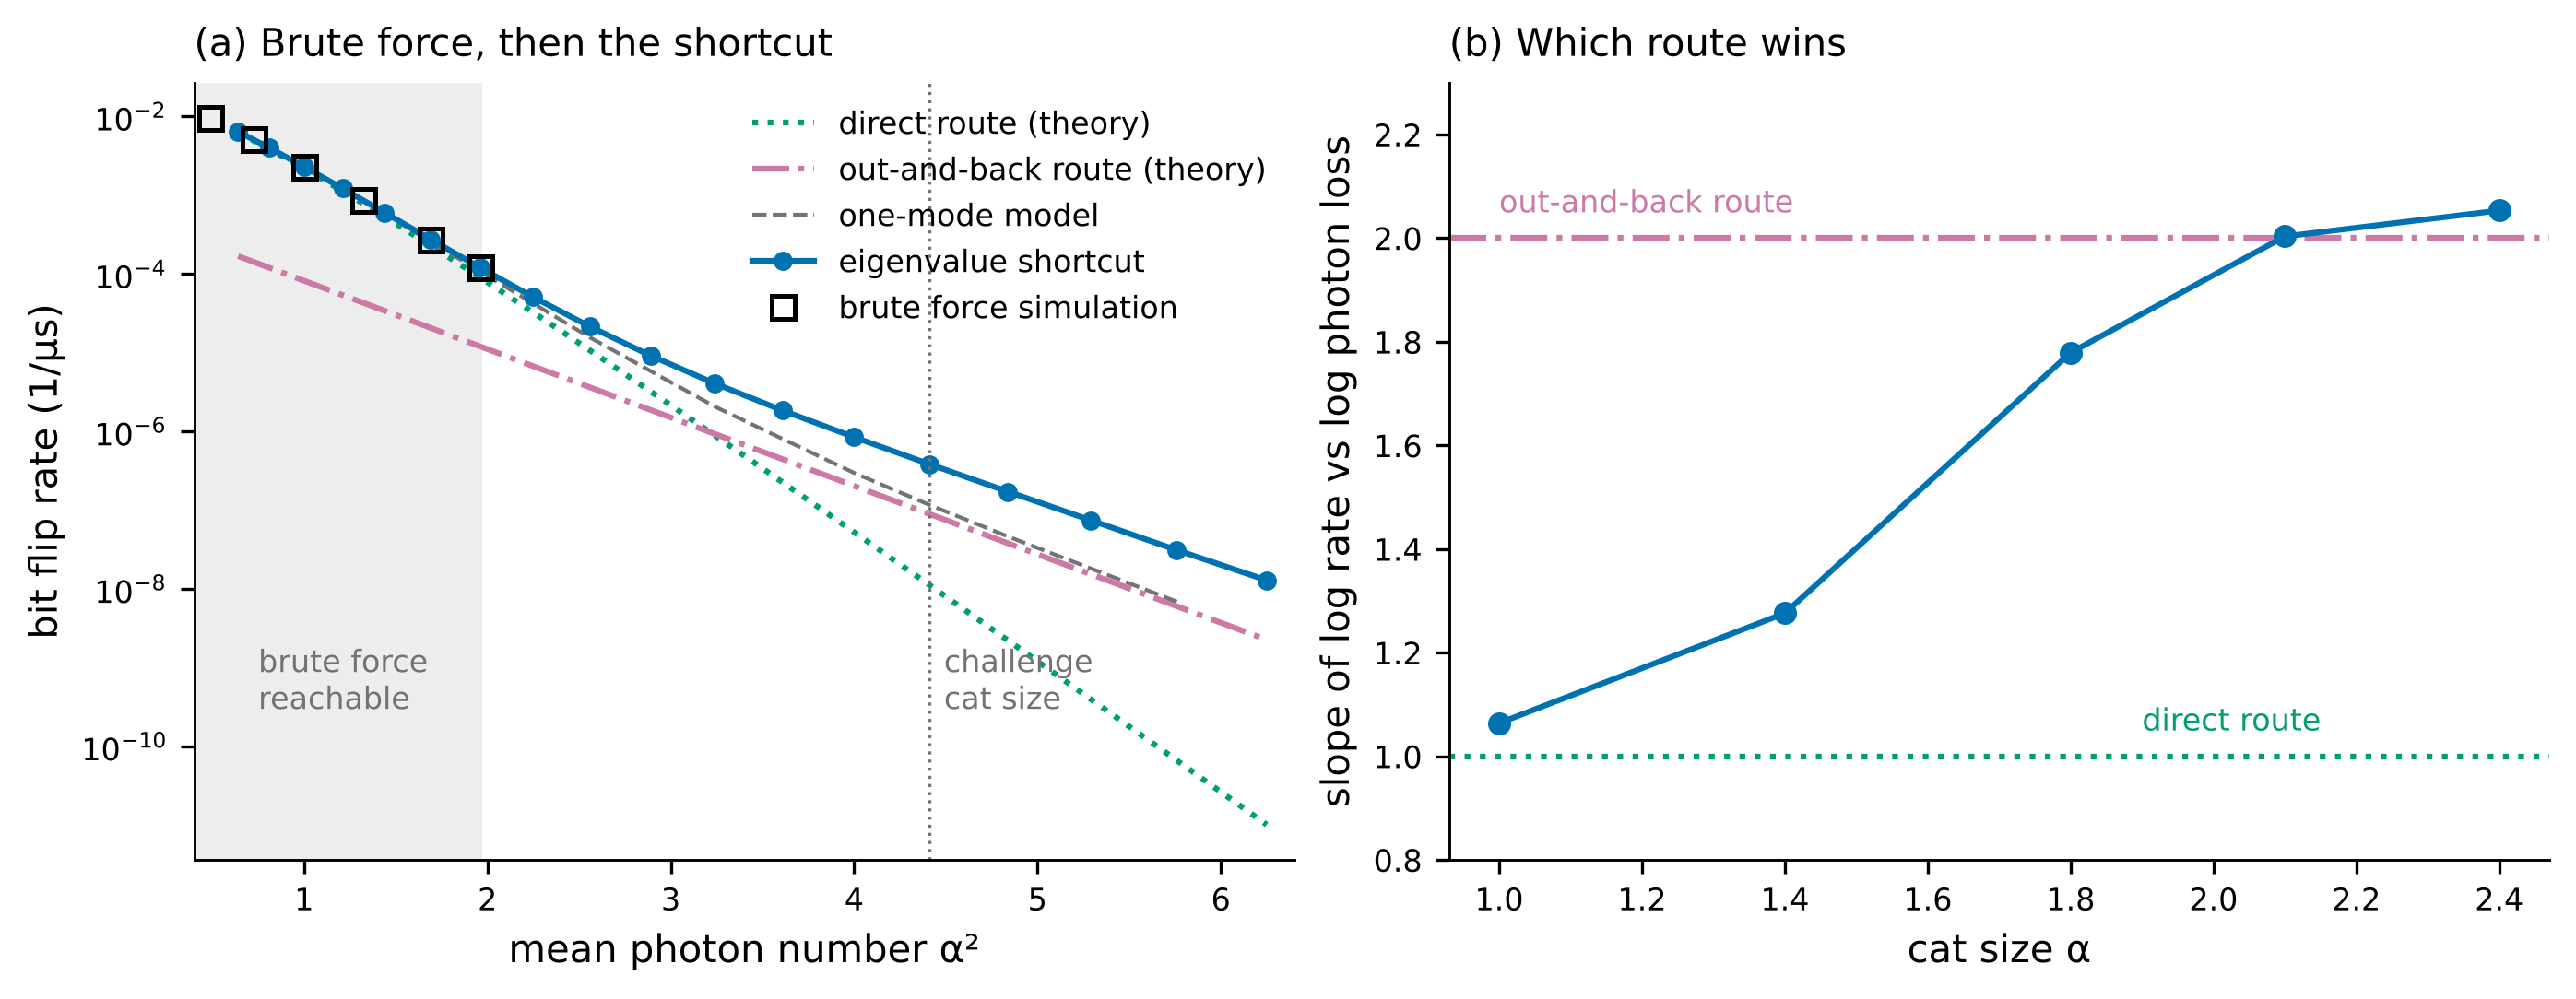

In [5]:
import io
from contextlib import redirect_stdout
from research.s2 import notebook_figs as F
from research.s2.notebook_figs import load, nominal, largest
with redirect_stdout(io.StringIO()):
    F.bit_flips()
display(Image(filename=str(ROOT / "figures/s2/task_2_1_large_cats.png"), width=1000))

**Brute force and the eigenvalue shortcut.** (a) $\Gamma_X$ versus $\alpha^2$. Open squares are the brute force fits from the figure above; blue circles are the slowest odd-block eigenvalue of the same two-mode model at its largest converged truncation, continued to $\alpha=2.5$. The shaded band is the range brute force can reach; the dotted line marks the challenge cat size $\alpha=2.1$. Green dotted: direct route $\kappa_a\alpha^2(\coth2\alpha^2-1)$, the direct-overlap estimate above. Pink dash-dotted: out-and-back route $(\kappa_a^2/\kappa_2)e^{-2\alpha^2}$, the second-order process of Dubovitskii. Grey dashed: one-mode model with the buffer eliminated. (b) Slope of $\ln\Gamma_X$ against $\ln\kappa_a$ from sweeping $\kappa_a\times\{\tfrac14,\tfrac12,1,2,4\}$. One photon loss per flip gives slope 1; two give slope 2.

In [6]:
td = {round(c["alpha"], 2): c["fit"]["gamma_per_us"] for c in result["cases"]}
eig = largest(d for d in load("gx_two_*.json") if nominal(d))
display(pd.DataFrame([{"alpha": a, "brute force (1/us)": f"{td[a]:.6e}", "eigenvalue (1/us)": f"{eig[a]['gamma_x']:.6e}",
                       "difference": f"{abs(eig[a]['gamma_x'] / td[a] - 1):.0e}"} for a in td if a in eig]))
display(pd.DataFrame([{"alpha": a, "Gamma_X (1/us)": f"{eig[a]['gamma_x']:.3e}", "one flip every": f"{1e-6 / eig[a]['gamma_x']:.2g} s",
                       "truncation": f"{eig[a]['na']}x{eig[a]['nb']}"} for a in (1.4, 1.8, 2.1, 2.4)]))

,alpha,brute force (1/us),eigenvalue (1/us),difference
0,1.0,2.300656e-03,2.300656e-03,6e-08
1,1.3,2.756441e-04,2.756478e-04,1e-05
2,1.4,1.202000e-04,1.202052e-04,4e-05


,alpha,Gamma_X (1/us),one flip every,truncation
0,1.4,1.202e-04,0.0083 s,22x12
1,1.8,4.067e-06,0.25 s,26x10
2,2.1,3.849e-07,2.6 s,28x12
3,2.4,3.115e-08,32 s,32x10


**Result.** Where both methods run they agree to better than $10^{-4}$. At the challenge cat size, **$\Gamma_X=3.85\times10^{-7}\ \mu\mathrm{s}^{-1}$: one bit flip every 2.6 s.**

The shortcut also resolves the exponent. The brute force fit gives $\gamma\approx3$ over $0.7\le\alpha\le1.4$, close to the direct-overlap estimate. Panel (b) shows why that value doesn't extend to larger cats: the slope moves from 1 to 2 between $\alpha=1.4$ and $2.1$, so the out-and-back process takes over, as the loss-strength check above anticipated. The local exponent falls from 3.1 to 1.86 by $\alpha=2.4$, consistent with the prompt's $\gamma\lesssim2$. The full model also flips 3.3× faster than the one-mode model at $\alpha=2.1$, because the buffer is slow. Eigenvalues change by less than 1.5% under larger truncations up to $\alpha=2.4$.